<a href="https://colab.research.google.com/github/Janani-Hendeniya/EN3160-Assignment-02/blob/main/230238R_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 02 - Fitting and Alignment

## Question 1: Blob Detection Using LoG

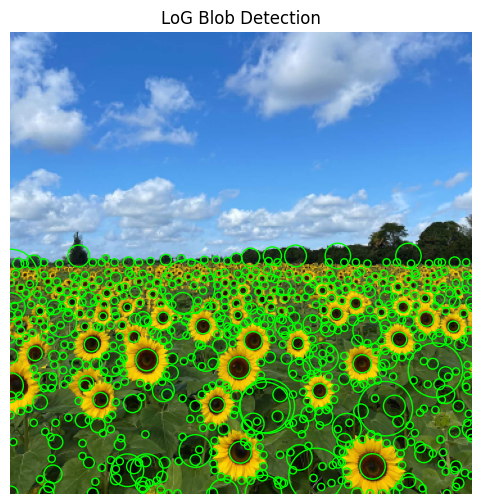

Detected circles: 657
Sigma range: 2 to 15


In [18]:

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

# Load image and convert to grayscale
image = cv.imread("the_berry_farms_sunflower_field.jpeg",
                  cv.IMREAD_REDUCED_COLOR_4)

if image is None:
    raise FileNotFoundError("Sunflower image not found")

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(float)
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Build scale-normalized LoG scale-space for dark blobs
sigmas = np.arange(2, 16)

scale_space = np.stack([
    np.maximum(s**2 * gaussian_laplace(gray, sigma=s), 0)
    for s in sigmas
])

# Detect 3D local maxima above threshold
maxima = maximum_filter(scale_space, size=(3, 3, 3))
mask = (scale_space == maxima) & (
    scale_space > 0.15 * scale_space.max()
)

# Extract circles below the horizon
horizon = int(gray.shape[0] * 0.48)
circles = []

for k, y, x in np.argwhere(mask):
    if y >= horizon:
        circles.append((x, y, np.sqrt(2) * sigmas[k]))

# Display detected circles
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image_rgb)

for x, y, r in circles:
    ax.add_patch(plt.Circle((x, y), r,
                            fill=False, color="lime", lw=1))

ax.set_title("LoG Blob Detection")
ax.axis("off")
plt.show()

print("Detected circles:", len(circles))
print("Sigma range:", sigmas[0], "to", sigmas[-1])


Reporting largest circles

In [17]:

# Report 10 largest detected circles
largest = sorted(circles, key=lambda c: c[2], reverse=True)[:10]

print("Largest detected circles (pixels):")
print("No.    X     Y     Radius     Sigma")

for i, (x, y, r) in enumerate(largest, 1):
    print(f"{i:<6} {x:<5} {y:<5} {r:>7.2f} {r/np.sqrt(2):>9.2f}")


Largest detected circles (pixels):
No.    X     Y     Radius     Sigma
1      0     190     21.21     15.00
2      138   198     21.21     15.00
3      331   263     21.21     15.00
4      200   291     21.21     15.00
5      292   293     21.21     15.00
6      238   345     21.21     15.00
7      198   292     19.80     14.00
8      197   359     14.14     10.00
9      144   326     12.73      9.00
10     91    341     12.73      9.00


Methodology

The sunflower field image was converted to grayscale, and scale-normalized Laplacian of Gaussian (LoG) filtering was applied over a range of $\sigma = 2$ to $15$, with a step size of $1$. Positive LoG responses were retained to detect dark-centred blobs. Local maxima were identified in the three-dimensional scale-space using a $3 \times 3 \times 3$ neighbourhood, with a response threshold of 15% of the maximum response. A spatial mask was applied to exclude the sky region.

Results

Detected blob centres were represented by circles with radii calculated using:

$$r = \sqrt{2}\sigma$$

The resulting circles had radii ranging from approximately 2.83 to 21.21 pixels. The largest detected circles were identified based on their estimated radii.

Discussion

The detector identified many dark sunflower centres, although some false detections occurred around leaves, background vegetation, and other dark regions. Restricting detections to the lower portion of the image reduced unwanted sky detections. However, the method remains sensitive to the selected scale range and response threshold.

# Question 2: Line and Circle Fitting Using RANSAC

## Part A: Generating the Noisy Point Set

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Generate noisy circle points
np.random.seed(0)

N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3

s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)

x = x0_gt + (r + n) * np.cos(t)
y = y0_gt + (r + n) * np.sin(t)

X_circ = np.column_stack((x, y))

# Generate noisy line points
s = 1.0
m, b = -1, 2

x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)

X_line = np.column_stack((x, y))

# Combine circle and line points
X = np.vstack((X_circ, X_line))

print("Total points:", len(X))
print("Circle points:", len(X_circ))
print("Line points:", len(X_line))


Total points: 100
Circle points: 50
Line points: 50


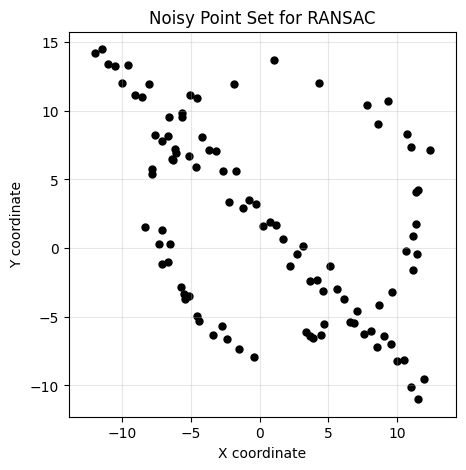

In [21]:
plt.figure(figsize=(5, 5))

plt.scatter(X[:, 0], X[:, 1], s=25, color="black")

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Noisy Point Set for RANSAC")
plt.axis("equal")
plt.grid(alpha=0.3)

plt.show()


## Question 2(a): RANSAC Line Fitting

In [22]:
# Construct a normalized line from two points
def line_from_points(p1, p2):
    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]

    length = np.hypot(dx, dy)

    if length < 1e-12:
        return None

    a = -dy / length
    b = dx / length
    d = a * p1[0] + b * p1[1]

    return np.array([a, b, d])


In [23]:
# Test the normalized line function

line = line_from_points(
    np.array([1, 2]),
    np.array([3, 4])
)

print("Line parameters [a, b, d]:", line)
print("Normal vector length:", np.linalg.norm(line[:2]))


Line parameters [a, b, d]: [-0.70710678  0.70710678  0.70710678]
Normal vector length: 0.9999999999999999


In [24]:
# Perpendicular distance from points to a line
def line_errors(points, line):
    a, b, d = line

    return np.abs(
        a * points[:, 0] +
        b * points[:, 1] - d
    )


In [25]:
test_points = np.array([[1, 1], [3, 1], [5, 5]])

errors = line_errors(test_points, line)

print("Perpendicular distances:", errors)


Perpendicular distances: [0.70710678 2.12132034 0.70710678]


In [26]:
# RANSAC line fitting implemented from scratch

def ransac_line(points, iterations=1000,
                threshold=1.5, min_inliers=35):

    rng = np.random.default_rng(42)

    best_line = None
    best_inliers = None
    best_sample = None
    best_count = 0

    for _ in range(iterations):

        # Randomly choose two different points
        indices = rng.choice(len(points), 2, replace=False)
        sample = points[indices]

        # Fit candidate line
        candidate = line_from_points(sample[0], sample[1])

        if candidate is None:
            continue

        # Calculate perpendicular distances
        errors = line_errors(points, candidate)

        # Identify inliers
        inliers = errors < threshold
        count = np.sum(inliers)

        # Keep the candidate with the most inliers
        if count > best_count:
            best_count = count
            best_line = candidate
            best_inliers = inliers
            best_sample = sample.copy()

    if best_count < min_inliers:
        raise ValueError("No line has enough inliers")

    return best_line, best_inliers, best_sample


In [27]:
# Estimate the line using RANSAC

best_line, line_inliers, line_sample = ransac_line(X)

print("Estimated line [a, b, d]:", best_line)
print("Number of line inliers:", np.sum(line_inliers))
print("Sample points:\n", line_sample)
print("Normal vector length:",
      np.linalg.norm(best_line[:2]))


Estimated line [a, b, d]: [0.69877621 0.71534035 1.6715574 ]
Number of line inliers: 57
Sample points:
 [[-9.06122449 11.18813658]
 [ 1.71428571  0.66213982]]
Normal vector length: 0.9999999999999999


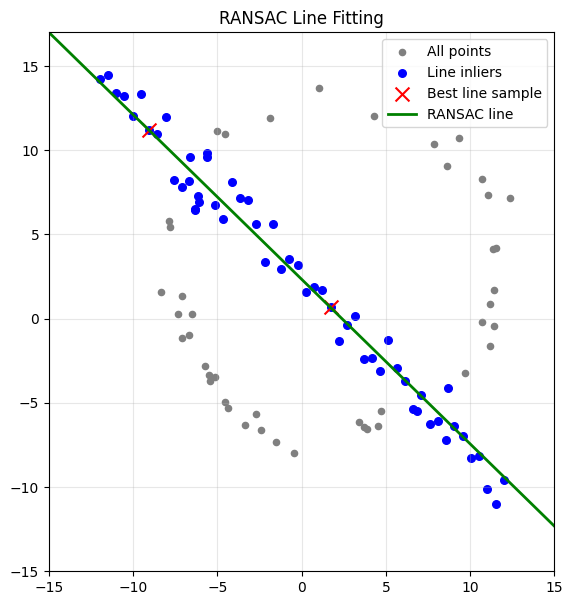

In [28]:
# Visualize RANSAC line estimation

fig, ax = plt.subplots(figsize=(7, 7))

# Plot all points
ax.scatter(X[:, 0], X[:, 1],
           s=20, color="gray", label="All points")

# Highlight line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],
           s=30, color="blue", label="Line inliers")

# Highlight the two sampled points
ax.scatter(line_sample[:, 0], line_sample[:, 1],
           s=100, marker="x", color="red",
           label="Best line sample")

# Draw estimated line
a, b, d = best_line
x_vals = np.linspace(-15, 15, 200)

if abs(b) > 1e-10:
    y_vals = (d - a * x_vals) / b
    ax.plot(x_vals, y_vals, "g-",
            linewidth=2, label="RANSAC line")
else:
    ax.axvline(d / a, color="green",
               linewidth=2, label="RANSAC line")

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("RANSAC Line Fitting")

plt.show()


In [29]:
# Refine the line using Total Least Squares

def fit_line_tls(points):
    center = points.mean(axis=0)
    centered = points - center

    _, _, vh = np.linalg.svd(centered)

    normal = vh[-1]
    a, b = normal
    d = np.dot(normal, center)

    return np.array([a, b, d])

refined_line = fit_line_tls(X[line_inliers])

print("RANSAC sampled line:", best_line)
print("Refined TLS line:", refined_line)
print("Refined normal length:",
      np.linalg.norm(refined_line[:2]))


RANSAC sampled line: [0.69877621 0.71534035 1.6715574 ]
Refined TLS line: [0.71564883 0.69846028 1.56177478]
Refined normal length: 0.9999999999999999


## Question 2(b): Circle Fitting Using RANSAC

In [30]:
# Remove the line inliers
X_remaining = X[~line_inliers]

print("Original number of points:", len(X))
print("Line inliers removed:", np.sum(line_inliers))
print("Remaining points:", len(X_remaining))


Original number of points: 100
Line inliers removed: 57
Remaining points: 43


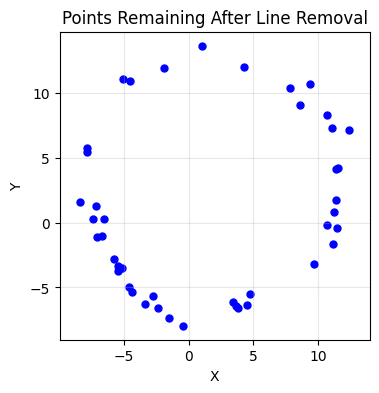

In [32]:
plt.figure(figsize=(4, 4))

plt.scatter(
    X_remaining[:, 0],
    X_remaining[:, 1],
    color="blue",
    s=25
)

plt.title("Points Remaining After Line Removal")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()


In [33]:
# Fit a circle through three points
def circle_from_points(p1, p2, p3):

    A = 2 * np.array([
        p2 - p1,
        p3 - p1
    ])

    B = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    # Reject collinear or nearly collinear samples
    if abs(np.linalg.det(A)) < 1e-8:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)

    return np.array([center[0], center[1], radius])


In [34]:
# Test circle construction with three known points

p1 = np.array([10.0, 0.0])
p2 = np.array([0.0, 10.0])
p3 = np.array([-10.0, 0.0])

test_circle = circle_from_points(p1, p2, p3)

print("Circle parameters [cx, cy, r]:", test_circle)


Circle parameters [cx, cy, r]: [-0.  0. 10.]


In [35]:
# Calculate radial errors for a circle
def circle_errors(points, circle):

    cx, cy, r = circle

    distances = np.sqrt(
        (points[:, 0] - cx)**2 +
        (points[:, 1] - cy)**2
    )

    return np.abs(distances - r)


In [36]:
test_points = np.array([
    [10.0, 0.0],
    [11.0, 0.0],
    [8.0, 0.0]
])

errors = circle_errors(
    test_points,
    np.array([0.0, 0.0, 10.0])
)

print("Radial errors:", errors)


Radial errors: [0. 1. 2.]


In [37]:
# RANSAC circle fitting implemented from scratch
def ransac_circle(points, iterations=2000,
                  threshold=1.25, min_inliers=25):

    rng = np.random.default_rng(42)

    best_circle = None
    best_inliers = None
    best_sample = None
    best_count = 0

    for _ in range(iterations):

        # Randomly select three different points
        indices = rng.choice(len(points), 3, replace=False)
        sample = points[indices]

        # Construct candidate circle
        candidate = circle_from_points(
            sample[0], sample[1], sample[2]
        )

        if candidate is None:
            continue

        # Measure radial error for each point
        errors = circle_errors(points, candidate)

        # Identify circle inliers
        inliers = errors < threshold
        count = np.sum(inliers)

        # Save the strongest consensus
        if count > best_count:
            best_count = count
            best_circle = candidate
            best_inliers = inliers
            best_sample = sample.copy()

    if best_count < min_inliers:
        raise ValueError("No circle has enough inliers")

    return best_circle, best_inliers, best_sample


In [38]:
# Estimate circle using remaining points
best_circle, circle_inliers, circle_sample = ransac_circle(
    X_remaining
)

print("Estimated circle [cx, cy, r]:", best_circle)
print("Number of circle inliers:", np.sum(circle_inliers))
print("Best sample points:")
print(circle_sample)


Estimated circle [cx, cy, r]: [ 1.9256625   3.126726   10.14596468]
Number of circle inliers: 43
Best sample points:
[[-4.53520657 10.94962636]
 [-7.86483023  5.78884008]
 [11.43226429 -0.41800553]]


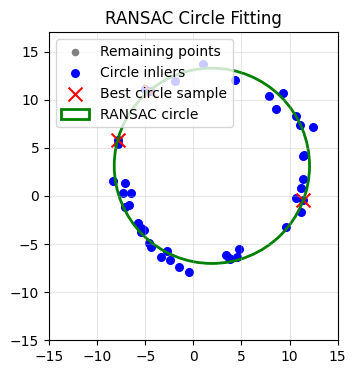

In [40]:
# Visualize RANSAC circle fitting
fig, ax = plt.subplots(figsize=(4, 4))

# Plot remaining points
ax.scatter(
    X_remaining[:, 0], X_remaining[:, 1],
    color="gray", s=20, label="Remaining points"
)

# Highlight circle inliers
ax.scatter(
    X_remaining[circle_inliers, 0],
    X_remaining[circle_inliers, 1],
    color="blue", s=30, label="Circle inliers"
)

# Highlight the best sample of three points
ax.scatter(
    circle_sample[:, 0], circle_sample[:, 1],
    color="red", marker="x", s=100,
    label="Best circle sample"
)

# Draw estimated RANSAC circle
cx, cy, r = best_circle

circle_patch = plt.Circle(
    (cx, cy), r,
    color="green", fill=False,
    linewidth=2, label="RANSAC circle"
)

ax.add_patch(circle_patch)

ax.set_aspect("equal")
ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("RANSAC Circle Fitting")

plt.show()


In [41]:
# Refine circle using all RANSAC inliers
from scipy.optimize import minimize

def circle_objective(params, points):
    cx, cy, r = params

    distances = np.sqrt(
        (points[:, 0] - cx)**2 +
        (points[:, 1] - cy)**2
    )

    return np.sum((distances - r)**2)

# Select circle inlier points
circle_points = X_remaining[circle_inliers]

# Minimize squared radial errors
result = minimize(
    circle_objective,
    best_circle,
    args=(circle_points,),
    bounds=[(None, None), (None, None), (1e-8, None)]
)

if not result.success:
    print("Warning: optimization reported:", result.message)

refined_circle = result.x

print("RANSAC circle:", best_circle)
print("Refined circle:", refined_circle)
print("Ground-truth circle: [2, 3, 10]")


RANSAC circle: [ 1.9256625   3.126726   10.14596468]
Refined circle: [1.86959015 3.06549708 9.94929261]
Ground-truth circle: [2, 3, 10]


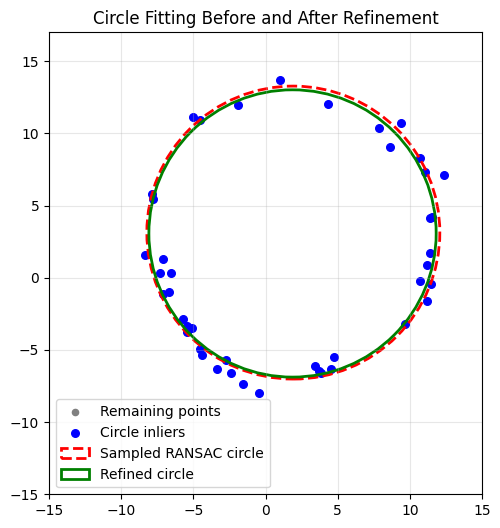

In [44]:
# Compare sampled and refined circle models

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    X_remaining[:, 0], X_remaining[:, 1],
    color="gray", s=20, label="Remaining points"
)

ax.scatter(
    circle_points[:, 0], circle_points[:, 1],
    color="blue", s=30, label="Circle inliers"
)

# Original sampled RANSAC circle
ax.add_patch(plt.Circle(
    best_circle[:2], best_circle[2],
    fill=False, color="red", linestyle="--",
    linewidth=2, label="Sampled RANSAC circle"
))

# Refined circle
ax.add_patch(plt.Circle(
    refined_circle[:2], refined_circle[2],
    fill=False, color="green",
    linewidth=2, label="Refined circle"
))

ax.set_aspect("equal")
ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("Circle Fitting Before and After Refinement")

plt.show()


## Question 2(c)

In [45]:
# Check that all required results are available
print("Total points:", len(X))
print("Line inliers:", np.sum(line_inliers))
print("Circle inliers:", np.sum(circle_inliers))

print("Sampled line:", best_line)
print("Refined line:", refined_line)

print("Sampled circle:", best_circle)
print("Refined circle:", refined_circle)


Total points: 100
Line inliers: 57
Circle inliers: 43
Sampled line: [0.69877621 0.71534035 1.6715574 ]
Refined line: [0.71564883 0.69846028 1.56177478]
Sampled circle: [ 1.9256625   3.126726   10.14596468]
Refined circle: [1.86959015 3.06549708 9.94929261]


In [46]:
# Helper function to draw a line ax + by = d
def draw_line(ax, line, color, label, linestyle="-"):
    a, b, d = line

    if abs(b) > 1e-10:
        x = np.linspace(-15, 15, 200)
        y = (d - a * x) / b
        ax.plot(x, y, color=color, linestyle=linestyle,
                linewidth=2, label=label)
    else:
        ax.axvline(d / a, color=color,
                   linestyle=linestyle,
                   linewidth=2, label=label)


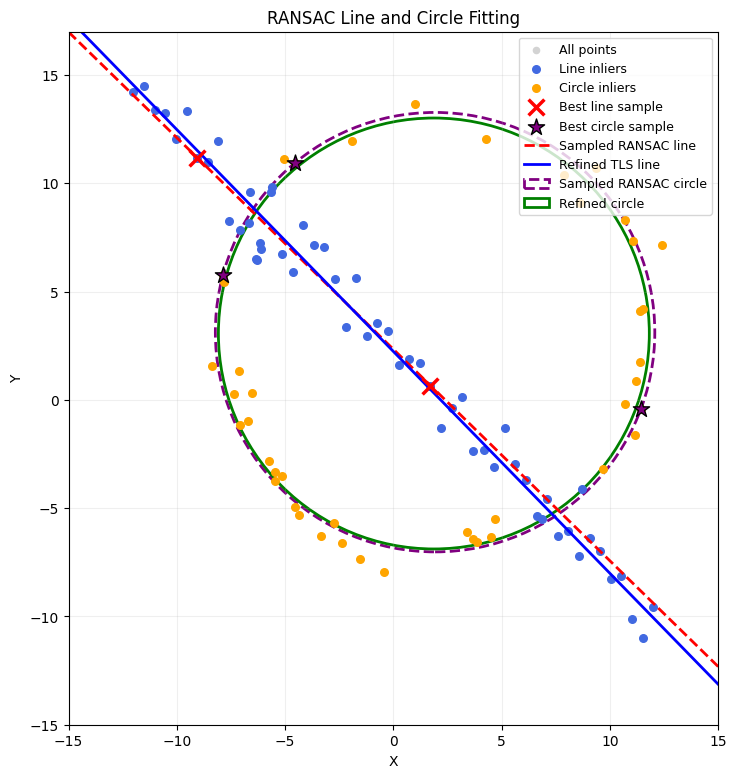

In [47]:
# Question 2(c): Final combined RANSAC visualization

fig, ax = plt.subplots(figsize=(9, 9))

# All original points
ax.scatter(X[:, 0], X[:, 1],
           color="lightgray", s=20,
           label="All points", zorder=1)

#Line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],
           color="royalblue", s=30,
           label="Line inliers", zorder=2)

#Circle inliers
circle_points = X_remaining[circle_inliers]
ax.scatter(circle_points[:, 0], circle_points[:, 1],
           color="orange", s=30,
           label="Circle inliers", zorder=2)

#Best line sample (2 points)
ax.scatter(line_sample[:, 0], line_sample[:, 1],
           marker="x", color="red", s=130,
           linewidths=2.5, label="Best line sample",
           zorder=4)

#Best circle sample (3 points)
ax.scatter(circle_sample[:, 0], circle_sample[:, 1],
           marker="*", color="purple", s=150,
           edgecolors="black",
           label="Best circle sample", zorder=4)

#Sampled RANSAC line
draw_line(ax, best_line, "red",
          "Sampled RANSAC line", "--")

#Refined TLS line
draw_line(ax, refined_line, "blue",
          "Refined TLS line")

#Sampled RANSAC circle
ax.add_patch(plt.Circle(
    best_circle[:2], best_circle[2],
    color="purple", fill=False,
    linestyle="--", linewidth=2,
    label="Sampled RANSAC circle"
))

#Refined circle
ax.add_patch(plt.Circle(
    refined_circle[:2], refined_circle[2],
    color="green", fill=False,
    linewidth=2, label="Refined circle"
))

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("RANSAC Line and Circle Fitting")
ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="upper right")

plt.show()


In [48]:
# Ground-truth line and circle for comparison

ground_truth_line = np.array([
    1 / np.sqrt(2),
    1 / np.sqrt(2),
    np.sqrt(2)
])

draw_line(ax, ground_truth_line, "black",
          "Ground-truth line", ":")

ax.add_patch(plt.Circle(
    (2, 3), 10,
    color="black", fill=False,
    linestyle=":", linewidth=1.5,
    label="Ground-truth circle"
))

# Update legend after adding ground truth
ax.legend(fontsize=8, loc="upper right")


In [49]:
# Evaluate model fitting errors

line_mae = np.mean(
    line_errors(X[line_inliers], refined_line)
)

circle_mae = np.mean(
    circle_errors(circle_points, refined_circle)
)

print(f"Line mean perpendicular error: {line_mae:.4f}")
print(f"Circle mean radial error: {circle_mae:.4f}")


Line mean perpendicular error: 0.6278
Circle mean radial error: 0.4670


In [50]:
plt.savefig(
    "question2_ransac_result.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


<Figure size 640x480 with 0 Axes>

## Question 2(d): Effect of Fitting the Circle First

In [51]:
# Fit the circle FIRST using all 100 points
circle_first, circle_first_inliers, circle_first_sample = ransac_circle(
    X, iterations=2000, threshold=1.25, min_inliers=25
)

print("Circle-first parameters [cx, cy, r]:", circle_first)
print("Circle-first inliers:", np.sum(circle_first_inliers))


Circle-first parameters [cx, cy, r]: [ 1.92377046  3.25610589 10.01486215]
Circle-first inliers: 58


In [52]:
# Remove circle inliers before fitting the line
X_after_circle = X[~circle_first_inliers]

print("Original points:", len(X))
print("Circle inliers removed:", np.sum(circle_first_inliers))
print("Points left for line fitting:", len(X_after_circle))


Original points: 100
Circle inliers removed: 58
Points left for line fitting: 42


In [53]:

# Fit the line AFTER removing circle inliers
line_second, line_second_inliers, line_second_sample = ransac_line(
    X_after_circle,
    iterations=1000,
    threshold=1.5,
    min_inliers=35
)

print("Line-second parameters [a, b, d]:", line_second)
print("Line-second inliers:", np.sum(line_second_inliers))


Line-second parameters [a, b, d]: [-0.71859945 -0.69542421 -1.38327362]
Line-second inliers: 41


In [54]:

# Refine the circle-first model
circle_first_points = X[circle_first_inliers]

result_first = minimize(
    circle_objective,
    circle_first,
    args=(circle_first_points,),
    bounds=[(None, None), (None, None), (1e-8, None)]
)

if not result_first.success:
    print("Circle optimization warning:", result_first.message)

refined_circle_first = result_first.x

# Refine the line fitted second
refined_line_second = fit_line_tls(
    X_after_circle[line_second_inliers]
)

print("Refined circle:", refined_circle_first)
print("Refined line:", refined_line_second)


Refined circle: [1.95209415 3.0538569  9.91503381]
Refined line: [-0.72315757 -0.69068309 -1.66383996]


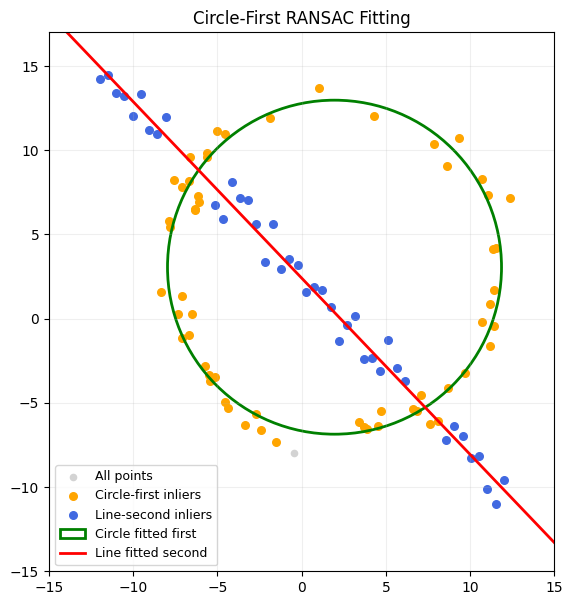

In [55]:

# Visualization: circle fitted first, then line

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(X[:, 0], X[:, 1],
           color="lightgray", s=20, label="All points")

ax.scatter(X[circle_first_inliers, 0],
           X[circle_first_inliers, 1],
           color="orange", s=30,
           label="Circle-first inliers")

ax.scatter(X_after_circle[line_second_inliers, 0],
           X_after_circle[line_second_inliers, 1],
           color="royalblue", s=30,
           label="Line-second inliers")

# Refined circle
ax.add_patch(plt.Circle(
    refined_circle_first[:2],
    refined_circle_first[2],
    color="green", fill=False,
    linewidth=2, label="Circle fitted first"
))

# Refined line
draw_line(ax, refined_line_second, "red",
          "Line fitted second")

ax.set_xlim(-15, 15)
ax.set_ylim(-15, 17)
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
ax.set_title("Circle-First RANSAC Fitting")

plt.show()


In [56]:

# Compare the fitting orders

def evaluate_models(line, circle):
    cx, cy, r = circle

    line_error = np.mean(line_errors(X_line, line))
    center_error = np.linalg.norm([cx - 2, cy - 3])
    radius_error = abs(r - 10)

    return line_error, center_error, radius_error

line_first_eval = evaluate_models(refined_line, refined_circle)
circle_first_eval = evaluate_models(refined_line_second, refined_circle_first)

print("Metric                   Line-first    Circle-first")
print("-" * 53)

names = ["Line mean error", "Circle center error", "Circle radius error"]

for name, a, b in zip(names, line_first_eval, circle_first_eval):
    print(f"{name:<25}{a:<14.4f}{b:.4f}")

print("\nInlier counts:")
print("Line-first line:", np.sum(line_inliers))
print("Line-first circle:", np.sum(circle_inliers))
print("Circle-first circle:", np.sum(circle_first_inliers))
print("Circle-first line:", np.sum(line_second_inliers))


Metric                   Line-first    Circle-first
-----------------------------------------------------
Line mean error          0.5502        0.5488
Circle center error      0.1459        0.0721
Circle radius error      0.0507        0.0850

Inlier counts:
Line-first line: 57
Line-first circle: 43
Circle-first circle: 58
Circle-first line: 41


### Question 2(d): Effect of Fitting the Circle First

To investigate the effect of fitting order, RANSAC was first applied to the complete point set to estimate the circle. The circle inliers were then removed, and line RANSAC was applied to the remaining points.

The fitting order affects the consensus sets because points near the intersection of the line and circle may be classified as inliers for either model. Removing these points during the first fitting stage changes the data available for estimating the second model.

The results demonstrate that sequential RANSAC fitting can be sensitive to:
- **Model fitting order**
- **Noise in the dataset**
- **Selected inlier thresholds**